# **AIRBNB DATASET PROJECT - STATISTICAL THINKING**


This is an analysis of Airbnb Boston listings dataset . The question we want to answer is: "What factors are associated with Airbnb prices, and can we quantify the uncertainty in those relationships?" we'll be following these steps:
### **Exploratory Data Analysis (EDA)**
    • What does the distribution of Airbnb prices look like? 
    • What's the median price? 
    • Are there extreme outliers? 
    • How does price vary by neighborhood? 
    • Reviews price
### **Probability / simulation** 
       What's the probability that a randomly selected Airbnb costs more than \$200/night? we'll calculate it directly, check it with a simulation, then measure the uncertainty around it with the bootstrap. 
### **Bootstrap** 
    For example: What's the 95% confidence interval for the probability that a listing costs more than \$200? We can bootstrap the dataset and construct the confidence interval ourselves rather than relying on a black-box function. 
### **Hypothesis testing** 
       Are Airbnb prices significantly different between two neighborhoods? Then we will perform a permutation test. 
### **Correlation**
       Is the number of reviews correlated with price? 
### **Linear regression**
    How much does price tend to change as the number of bedrooms increases? Then we build a regression and use a pairs bootstrap to estimate uncertainty around the slope.

## LOADING THE LIBRARIES AND THE DATA

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib as mpl
import matplotlib.dates as mdates
import statsmodels.api as sm
from scipy import stats
from scipy.stats import pearsonr
from scipy.stats import spearmanr

plt.style.use('ggplot')
%matplotlib inline

In [2]:
from pathlib import Path
data_path = Path("listings.csv")
data_listing = pd.read_csv(data_path)

In [3]:
data_listing.info()

<class 'pandas.DataFrame'>
RangeIndex: 3585 entries, 0 to 3584
Data columns (total 95 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   id                                3585 non-null   int64  
 1   listing_url                       3585 non-null   str    
 2   scrape_id                         3585 non-null   int64  
 3   last_scraped                      3585 non-null   str    
 4   name                              3585 non-null   str    
 5   summary                           3442 non-null   str    
 6   space                             2528 non-null   str    
 7   description                       3585 non-null   str    
 8   experiences_offered               3585 non-null   str    
 9   neighborhood_overview             2170 non-null   str    
 10  notes                             1610 non-null   str    
 11  transit                           2295 non-null   str    
 12  access           

## **EXPLORATORY DATA ANALYSIS**

We Load the data and keep the columns we need
The raw file has 95 columns, mostly text (descriptions, URLs, host bios). We keep only the variables relevant to our question (What factors are associated with Airbnb prices, and can we quantify the uncertainty in those relationships?)

We use neighbourhood_cleansed (a tidy, standardized neighborhood field) rather than neighbourhood (free-text from hosts, with 543 missing values).

In [4]:
print("Raw shape:", data_listing.shape)

cols = ["id", "neighbourhood_cleansed", "room_type", "property_type", "accommodates",
        "bedrooms", "bathrooms", "price", "minimum_nights",
        "number_of_reviews", "review_scores_rating", "reviews_per_month"]
data = data_listing[cols].copy()
data.head()

Raw shape: (3585, 95)


,id,neighbourhood_cleansed,room_type,property_type,accommodates,bedrooms,bathrooms,price,minimum_nights,number_of_reviews,review_scores_rating,reviews_per_month
0,12147973,Roslindale,Entire home/apt,House,4,2.0,1.5,$250.00,2,0,NaN,NaN
1,3075044,Roslindale,Private room,Apartment,2,1.0,1.0,$65.00,2,36,94.0,1.30
2,6976,Roslindale,Private room,Apartment,2,1.0,1.0,$65.00,3,41,98.0,0.47
3,1436513,Roslindale,Private room,House,4,1.0,1.0,$75.00,1,1,100.0,1.00
4,7651065,Roslindale,Private room,House,2,1.0,1.5,$79.00,2,29,99.0,2.25


In [5]:
missing = (data.isna().mean() * 100).round(1)
missing[missing > 0].rename("% missing")

property_type            0.1
bedrooms                 0.3
bathrooms                0.4
review_scores_rating    22.7
reviews_per_month       21.1
Name: % missing, dtype: float64

**Interpretation.** Almost nothing is missing in the structural columns (property_type 0.1%, bedrooms 0.3%, bathrooms 0.4%), so dropping those rows later costs us almost nothing.

The review variables are different: about 22.7% of listings have no `review_scores_rating` and 21.1% have no `reviews_per_month`. These are **mostly** listings that have never been reviewed. (The two percentages differ a little, so a few listings have reviews but no rating.)

The values are missing for a *reason* (no guests yet), not at random. If we deleted these listings we would only keep listings that have already hosted guests, and our picture of the market would be biased. So we keep them, and only drop them in the specific analysis that needs a rating (correlation with ratings).

* **What does the distribution of Airbnb prices look like?**

In [6]:
# First lets get the prices from str to float 
price_data_list = data['price'].tolist()
price_list = [float(item.replace(',' , '')[1:]) for item in price_data_list]
data['price'] = price_list
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 3585 entries, 0 to 3584
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id                      3585 non-null   int64  
 1   neighbourhood_cleansed  3585 non-null   str    
 2   room_type               3585 non-null   str    
 3   property_type           3582 non-null   str    
 4   accommodates            3585 non-null   int64  
 5   bedrooms                3575 non-null   float64
 6   bathrooms               3571 non-null   float64
 7   price                   3585 non-null   float64
 8   minimum_nights          3585 non-null   int64  
 9   number_of_reviews       3585 non-null   int64  
 10  review_scores_rating    2772 non-null   float64
 11  reviews_per_month       2829 non-null   float64
dtypes: float64(5), int64(4), str(3)
memory usage: 336.2 KB


**What does the distribution of price look like?**
I use histograms to show shape, centre, spread and unusual values. I plot raw prices and **log prices** side by side. The log compresses very large values, which makes a right-skewed variable easier to read.

count       3585.000000
mean         173.925802
median       150.000000
std dev      148.331321
min           10.000000
25th pct      85.000000
75th pct     220.000000
95th pct     375.000000
max         4000.000000
skewness       8.517918


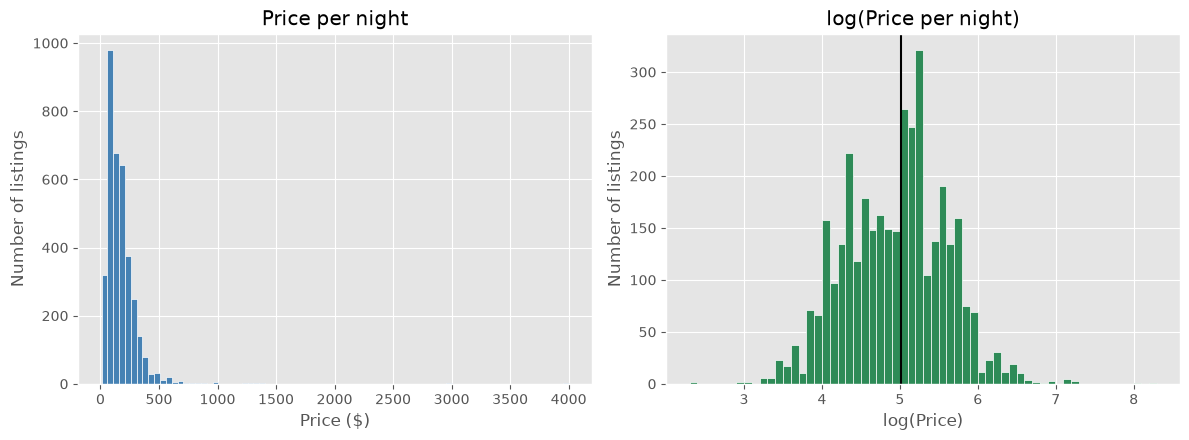

In [7]:
data["log_price"] = np.log(data["price"])
p = data["price"]
summary = pd.Series({
    "count": len(p), "mean": p.mean(), "median": p.median(), "std dev": p.std(),
    "min": p.min(), "25th pct": p.quantile(.25), "75th pct": p.quantile(.75),
    "95th pct": p.quantile(.95), "max": p.max(), "skewness": stats.skew(p),
})
print(summary.to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].hist(p, bins=80, color="steelblue", edgecolor="white")
ax[0].set(title="Price per night", xlabel="Price ($)", ylabel="Number of listings");

ax[1].hist(data["log_price"], bins=60, color="seagreen", edgecolor="white")
ax[1].axvline(data["log_price"].median(), color="black")
ax[1].set(title="log(Price per night)", xlabel="log(Price)", ylabel="Number of listings")
plt.tight_layout(); plt.show()

These statistics show that prices are **strongly right-skewed** with a lot of variability.
- The average price is about \$174, and the **median is \$150**: half the listings cost \$150 or less.
- Mean > median is a classic sign of right skew. A few very expensive listings pull the mean up, while the median barely moves.
- **Skewness = 8.5.** It is positive (long right tail) and far above 1, which is usually considered strongly skewed.
- Min = \$10 and max = \$4,000. 75% of listings cost \$220 or less and 95% cost \$375 or less, so a \$4,000 listing is extremely far from the rest.
- Standard deviation = \$148, about 85% of the mean, so prices vary a lot.

**Reading the plots.** In the raw histogram almost everything is squeezed under \$500 and the long tail stretches to \$4,000, so we can't see any detail. After taking logs the histogram is much more **symmetric and bell-shaped**, with a median around 5 (e⁵ ≈ \$150, the black line). It has two bumps, around \$80 and \$180, which fit the typical prices of private rooms and entire homes (see the room type table below). That is a hint that room type matters.

In [8]:
# IQR method
Q1 = np.percentile(data['price'], 25)
Q3 = np.percentile(data['price'], 75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = [p for p in data['price']
            if p < lower_bound or p > upper_bound]


n_out = (p > upper_bound).sum()
print(f"IQR = {IQR:.0f}; Tukey fences = [{lower_bound:.0f}, {upper_bound:.0f}]")
print(f"Listings above the upper fence: {n_out} ({n_out / len(p):.1%})")
print(f"Listings at or above $1,000/night: {(p >= 1000).sum()}")

print("\nTen most expensive listings:")
display(data.nlargest(10, "price")[["price", "room_type", "bedrooms", "accommodates", "neighbourhood_cleansed"]])

print("Ten cheapest listings:")
display(data.nsmallest(10, "price")[["price", "room_type", "bedrooms", "accommodates", "neighbourhood_cleansed"]])

IQR = 135; Tukey fences = [-118, 422]
Listings above the upper fence: 124 (3.5%)
Listings at or above $1,000/night: 12

Ten most expensive listings:


,price,room_type,bedrooms,accommodates,neighbourhood_cleansed
2285,4000.0,Entire home/apt,1.0,4,Fenway
3055,3000.0,Entire home/apt,2.0,4,South Boston Waterfront
793,1400.0,Private room,1.0,2,Roxbury
2204,1372.0,Private room,1.0,1,Fenway
1950,1345.0,Entire home/apt,1.0,4,Beacon Hill
1022,1300.0,Entire home/apt,5.0,8,South End
2448,1275.0,Private room,1.0,2,Fenway
1262,1250.0,Entire home/apt,3.0,5,Back Bay
3096,1250.0,Entire home/apt,1.0,2,South Boston Waterfront
1896,1235.0,Entire home/apt,1.0,3,Beacon Hill


Ten cheapest listings:


,price,room_type,bedrooms,accommodates,neighbourhood_cleansed
2033,10.0,Private room,1.0,2,Downtown
3468,11.0,Entire home/apt,1.0,2,Allston
471,20.0,Shared room,1.0,1,Mission Hill
3450,20.0,Private room,1.0,1,Allston
267,22.0,Shared room,1.0,1,Jamaica Plain
777,22.0,Shared room,1.0,1,Roxbury
382,25.0,Private room,1.0,2,Jamaica Plain
2799,25.0,Shared room,1.0,1,Dorchester
3529,25.0,Private room,1.0,2,Allston
84,27.0,Private room,1.0,1,Jamaica Plain


IQR = 135, so the fences are [−118, 422]. The lower fence is negative, so no listing can be a *low* outlier by this rule. 124 listings (3.5%) are above \$422, and 12 cost \$1,000 or more.

Some high prices are plausible (a 5-bedroom entire home for \$1,300 that fits 8 people). Others are suspicious: a 1-bedroom for \$4,000 in Fenway, or a *private room for 1 person* at \$1,372. They could be typos, special-event pricing or placeholder prices. At the other end, an *entire home* at \$11 is also doubtful. We can't know from the data alone.

The IQR rule only flags values *far from the middle*, not values that are *wrong*. I keep them for now, but they strongly affect the mean, the standard deviation, Pearson correlation and the regression line. That is why I use medians, Spearman correlation and log prices.

• **How does price vary by neighborhood?**

Neighborhoods in data: 25 | with n >= 30: 21


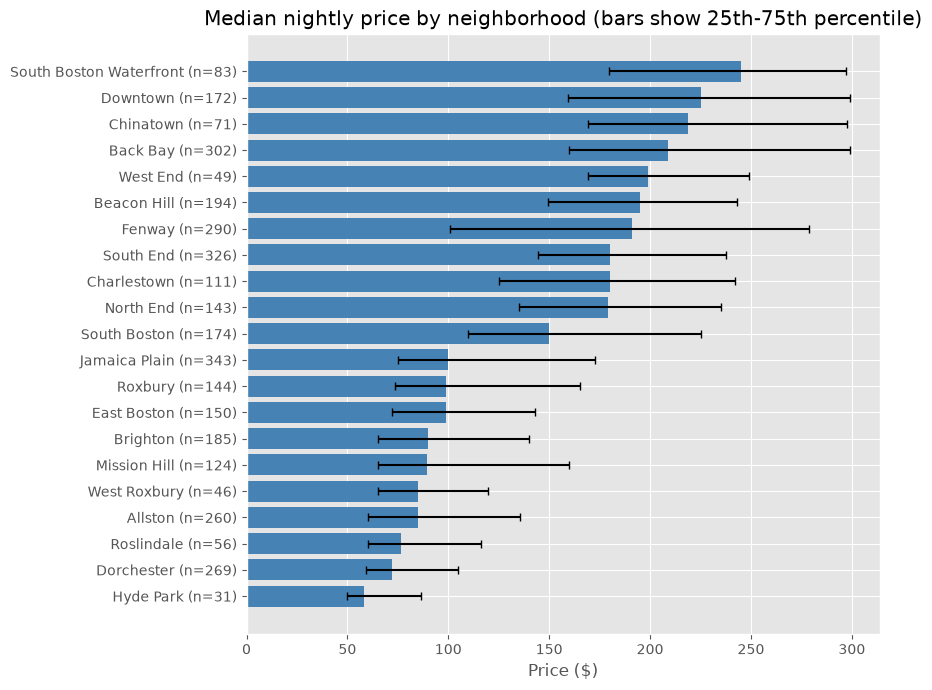

,n,median,mean,q25,q75
neighbourhood_cleansed,,,,,
South Boston Waterfront,83,245.0,306.060241,179.5,297.0
Downtown,172,225.0,236.459302,159.5,299.0
Chinatown,71,219.0,232.352113,169.0,297.5
Back Bay,302,209.0,240.950331,160.0,299.0
West End,49,199.0,209.591837,169.0,249.0


In [9]:
by_nbh = (data.groupby("neighbourhood_cleansed")["price"]
             .agg(n="size", median="median", mean="mean",
                  q25=lambda s: s.quantile(.25), q75=lambda s: s.quantile(.75)))
print("Neighborhoods in data:", len(by_nbh), "| with n >= 30:", (by_nbh["n"] >= 30).sum())
by_nbh = by_nbh[by_nbh["n"] >= 30].sort_values("median")

fig, ax = plt.subplots(figsize=(9, 7))
err = [by_nbh["median"] - by_nbh["q25"], by_nbh["q75"] - by_nbh["median"]]
ax.barh(by_nbh.index, by_nbh["median"], xerr=err, color="steelblue", capsize=3)

# Add listing counts beside neighborhood names on the y-axis
ax.set_yticks(range(len(by_nbh)))
ax.set_yticklabels([
    f"{neighborhood} (n={n})"
    for neighborhood, n in zip(by_nbh.index, by_nbh["n"])])

ax.set(title="Median nightly price by neighborhood (bars show 25th-75th percentile)", xlabel="Price ($)")
plt.tight_layout(); plt.show()

by_nbh.sort_values("median", ascending=False).head(5)

I only keep neighborhoods with **at least 30 listings** (21 of the 25), because a median based on a handful of listings is unreliable. I use the **median** instead of the mean because prices are skewed 

Prices vary a lot by neighborhood.
- **Most expensive (median):** South Boston Waterfront (\$245), Downtown (\$225), Chinatown (\$219), Back Bay (\$209), West End (\$199).
- **Cheapest:** Hyde Park (\$58), Dorchester (\$72), Roslindale (\$76.5).
- The bars show the middle 50% of prices. The cheaper neighborhoods have shorter bars (more consistent prices), while Fenway and Back Bay have long bars (a wide mix of cheap and expensive listings)..

### Median price by room type, and a check on confounding

In [10]:
print("Median price by room type:")
print(data.groupby("room_type")["price"].agg(n="size", median="median").to_string(), "\n")

confound = pd.DataFrame({
    "median_all": by_nbh["median"],
    "pct_entire_home": data.groupby("neighbourhood_cleansed")["room_type"]
                         .apply(lambda s: (s == "Entire home/apt").mean() * 100),
    "median_entire_homes_only": data[data["room_type"] == "Entire home/apt"]
                         .groupby("neighbourhood_cleansed")["price"].median(),
}).loc[by_nbh.index].sort_values("median_all", ascending=False)
confound

Median price by room type:
                    n  median
room_type                    
Entire home/apt  2127   199.0
Private room     1378    80.0
Shared room        80    60.0 



,median_all,pct_entire_home,median_entire_homes_only
neighbourhood_cleansed,,,
South Boston Waterfront,245.0,85.542169,250.0
Downtown,225.0,83.720930,229.5
Chinatown,219.0,87.323944,227.0
Back Bay,209.0,87.086093,225.0
West End,199.0,87.755102,199.0
Beacon Hill,195.0,79.896907,200.0
Fenway,191.0,71.724138,219.0
South End,180.0,76.687117,199.0
Charlestown,180.0,61.261261,214.5


Room type is strongly related to price: the median is \$199 for entire homes, \$80 for private rooms and \$60 for shared rooms.

Room type mix also differs across neighborhoods: about 87% of Back Bay and Chinatown listings are entire homes, versus only 25% in Dorchester and 19% in Hyde Park. So part of the "expensive neighborhood" pattern is really a "more entire apartments" pattern. When a third variable (room type) is linked to both things we compare (neighborhood and price), it is called a **confounder**.

Looking at entire homes only, the spread across neighborhoods shrinks from roughly 4x (\$245 vs \$58) to roughly 2x (\$250 vs \$125). For example Dorchester goes from \$72 overall to \$150 for entire homes, and Jamaica Plain from \$100 to \$175. Back Bay and the Waterfront are still at the top, so neighborhood still matters.

## **PROBABILITY AND SIMULATION**

**What is the probability that a randomly selected Airbnb costs more than $200 per night?**

To answer the question, I will:
1. calculate the probability **directly** from the data,
2. **check** it by simulating random picks (Monte Carlo),
3. use a **bootstrap** to measure how uncertain the estimate is.

In [11]:
plt.rcParams["figure.figsize"] = (8, 4.5)

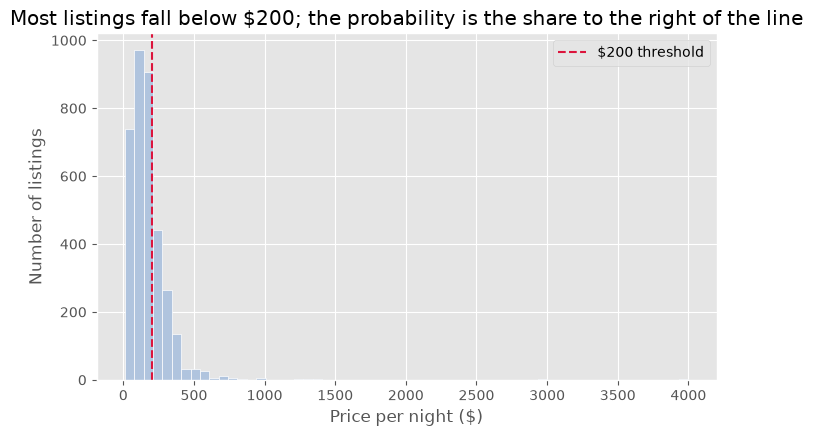

In [12]:
# First let's get a refresher on what the distribution of prices looks like with the $200 threshold

fig, ax = plt.subplots()
ax.hist(data["price"], bins=60, color="lightsteelblue", edgecolor="white")
ax.axvline(200, color="crimson", linestyle="--", label="$200 threshold")
ax.set_xlabel("Price per night ($)")
ax.set_ylabel("Number of listings")
ax.set_title("Most listings fall below $200; the probability is the share to the right of the line")
ax.legend()
plt.show()

In [13]:
# Calculate the probability from the data
p_hat = (data["price"] > 200).mean()
print(f"P(price > $200) = {p_hat:.3f}")

P(price > $200) = 0.278


About 27.8% of the listings in the dataset cost more than \$200 per night, so P(price > \$200) ≈ 0.278.
This is an *empirical probability*: the proportion of listings that satisfy the condition.

I pick a random listing (every listing equally likely, and **with replacement**, so the same listing can be picked twice), record whether its price is above \$200, and repeat 10,000 times. The share of "above \$200" outcomes across all picks is the simulated probability.

This is a Monte Carlo simulation. If the direct calculation is correct, the two answers should be very close.

In [14]:
# Confirm it with a simulation
rng = np.random.default_rng(42)
draws = rng.choice(data["price"].values, size=10_000, replace=True)
p_sim = (draws > 200).mean()
print(f"Simulated: {p_sim:.3f}")

Simulated: 0.279


The simulation gives 0.279, compared to 0.278 from the direct calculation. The tiny gap is just random luck in 10,000 draws. That luck has a size of about √(0.278 × 0.722 / 10,000) ≈ 0.0045, so a gap of 0.001 is well within it.

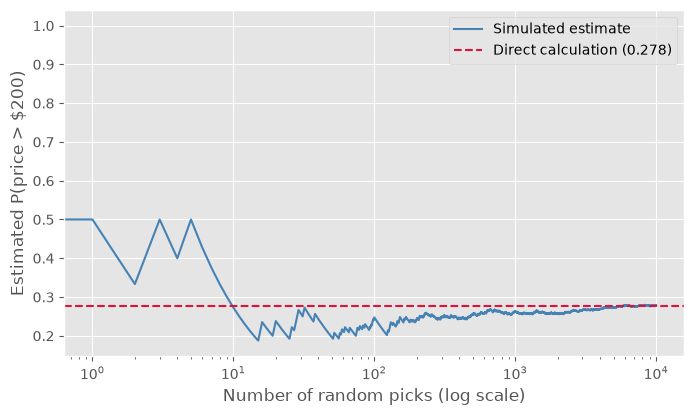

In [15]:
running = np.cumsum(draws > 200) / np.arange(1, len(draws) + 1)

fig, ax = plt.subplots()
ax.plot(running, color="steelblue", label="Simulated estimate")
ax.axhline(p_hat, color="crimson", linestyle="--", label=f"Direct calculation ({p_hat:.3f})")
ax.set_xscale("log")   
ax.set_xlabel("Number of random picks (log scale)")
ax.set_ylabel("Estimated P(price > $200)")
ax.legend()
plt.show()

With few picks the estimate swings widely, but as the number of picks grows it settles on the direct calculation (0.278). This is the **law of large numbers**: more repetitions means the simulated proportion gets closer to the true proportion. The x-axis is on a log scale so we can see the early swings.

## **Bootstrap**

My dataset is one sample, and a different sample of listings would give a slightly different proportion. To see how much the estimate varies, I use the **bootstrap**: draw a new sample of the **same size as the data (n = 3,585)** with replacement, recompute the proportion above \$200, and repeat 5,000 times. The middle 95% of these proportions is the 95% confidence interval.

*Difference with the previous simulation:* there, more draws meant less simulation error. Here each resample must have the same size n as the real data, because we want to imitate "what would another sample of n listings look like?".

In [16]:
# Quantify the uncertainty with a bootstrap
n = len(data)
boot = [(rng.choice(data["price"].values, size=n, replace=True) > 200).mean()
        for _ in range(5000)]
ci = np.percentile(boot, [2.5, 97.5])
print(f"95% CI: ({ci[0]:.3f}, {ci[1]:.3f})")

95% CI: (0.263, 0.292)


The 95% bootstrap confidence interval is (0.263, 0.292), so the true proportion is plausibly between 26.3% and 29.2%.

The interval is narrow because the sample is large (n = 3,585). With a smaller sample the interval would be wider. 

## **HYPOTHESIS TESTING**

Are Airbnb prices significantly different between two neighborhoods? Then we will perform a permutation test. 

Comparison 1: Back Bay vs. Dorchester

**H₀:** Back Bay and Dorchester listing prices come from the same distribution (neighborhood is unrelated to price)
**H₁:** The median prices differ (two-sided).
**Test statistic:** difference in median price (Back Bay − Dorchester).
**Significance level:** α = 0.05, set before running the test.
**Why this pair:** a central, tourist-oriented area vs. a large residential one, so I expect a difference.

If H₀ is true, the neighborhood label means nothing: a Back Bay listing could just as well have been a Dorchester one. So I **shuffle the labels** (pool all prices, then split them randomly into two groups of the original sizes), compute the difference in medians, and repeat 10,000 times. This gives the differences we get **by chance alone**. The **p-value** is the fraction of shuffles whose gap is at least as big as the real one (in absolute value, because the test is two-sided).

In [17]:
def perm_test(a, b, stat=np.median, n_perm=10_000, seed=42):
    """Two-sided permutation test for a difference in `stat` between a and b."""
    rng = np.random.default_rng(seed)
    obs = stat(a) - stat(b)
    pooled = np.concatenate([a, b])
    n_a = len(a)

    perm_diffs = np.empty(n_perm)
    for i in range(n_perm):
        shuffled = rng.permutation(pooled)
        perm_diffs[i] = stat(shuffled[:n_a]) - stat(shuffled[n_a:])

    # +1 in numerator and denominator avoids reporting p = 0 exactly
    p_value = (np.sum(np.abs(perm_diffs) >= abs(obs)) + 1) / (n_perm + 1)
    return obs, perm_diffs, p_value


def plot_perm(obs, perm_diffs, title, xlabel="Difference in median price under H₀ ($)"):
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.hist(perm_diffs, bins=50, color="lightsteelblue", edgecolor="white")
    ax.axvline(obs, color="crimson", label=f"Observed ({obs:.1f})")
    ax.axvline(-obs, color="crimson", linestyle="--")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Frequency")
    ax.set_title(title)
    ax.legend()
    plt.show()

302 269
Observed difference in medians: $137.00
p-value: 0.0001


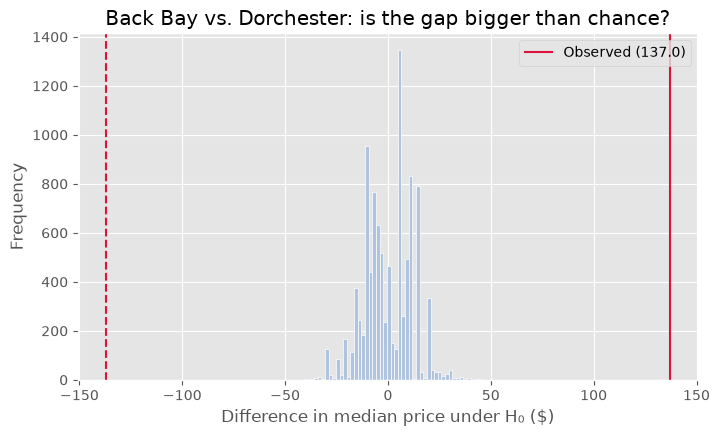

In [18]:
def get_prices(data, name):
    return data.loc[data["neighbourhood_cleansed"] == name, "price"].values

a = get_prices(data, "Back Bay")
b = get_prices(data, "Dorchester")
print(len(a), len(b))

obs, perm_diffs, p_value = perm_test(a, b, stat=np.median)
print(f"Observed difference in medians: ${obs:.2f}")
print(f"p-value: {p_value:.4f}")

plot_perm(obs, perm_diffs, "Back Bay vs. Dorchester: is the gap bigger than chance?")

n = 302 (Back Bay) and 269 (Dorchester). Observed difference in medians = \$137 (\$209 − \$72).

**p-value.** With 10,000 shuffles, the smallest p we can get is 1/10,001 ≈ 0.0001. So "p = 0.0001" really means **none of the 10,000 shuffles produced a gap as big as \$137**. 

Since p < 0.05, I reject H₀: there is strong evidence that the median prices differ. The gap of \$137 is the **effect size** (how big the difference is in dollars). The p-value only says it is unlikely to be chance, not how important it is.

Comparison 2: Allston vs. Brighton

**H₀:** Allston and Brighton listing prices come from the same distribution (neighborhood is unrelated to price), so the difference in median price is due to chance.
**H₁:** The median prices differ (two-sided).
**Test statistic:** difference in median price (Allston − Brighton).
**Significance level:** α = 0.05, set before running the test.
**Why this pair:** The two neighborhoods are adjacent and similar, so I expect little or no difference.

260 185
Observed difference in medians: $-5.00
p-value: 0.4433


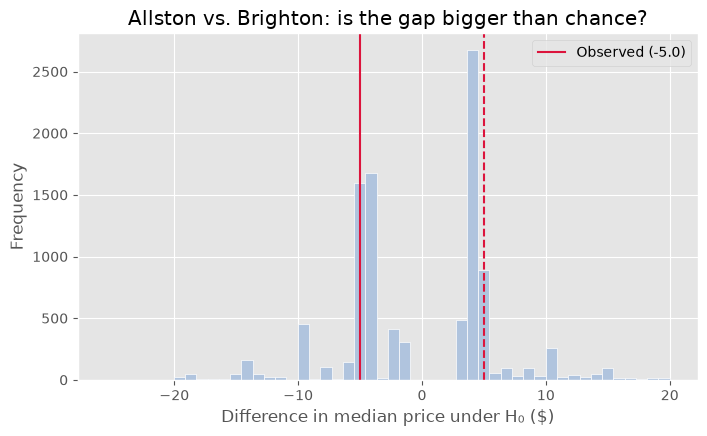

In [19]:
def get_prices(data, name):
    return data.loc[data["neighbourhood_cleansed"] == name, "price"].values

c = get_prices(data, "Allston")
d = get_prices(data, "Brighton")
print(len(c), len(d))

obs, perm_diffs, p_value = perm_test(c, d, stat=np.median)
print(f"Observed difference in medians: ${obs:.2f}")
print(f"p-value: {p_value:.4f}")

plot_perm(obs, perm_diffs, "Allston vs. Brighton: is the gap bigger than chance?")

n = 260 (Allston) and 185 (Brighton). Observed difference in medians = −\$5 (\$85 − \$90), p = 0.443. About 44% of random shuffles give a gap at least this large, so a \$5 gap is completely ordinary. Since p ≥ 0.05, I **fail to reject H₀**.

This does **not prove** the two neighborhoods are identical. It only says this data can't tell them apart. 

Let's also look at the **mean** differences. Medians ignore extreme prices, while means are pulled by them. If both statistics give the same conclusion, our result doesn't depend on that choice.

In [20]:
obs_m, _, p_m = perm_test(a, b, stat=np.mean)
print(f"Mean difference: ${obs_m:.2f}, p = {p_m:.4f}")

Mean difference: $149.31, p = 0.0001


 **Interpretation (Back Bay − Dorchester).** Mean difference = \$149.31 (a bit bigger than the \$137 median gap, because expensive listings pull the means up), p = 0.0001. Same conclusion as with medians: reject H₀.

In [21]:
obs_m, _, p_m = perm_test(c, d, stat=np.mean)
print(f"Mean difference: ${obs_m:.2f}, p = {p_m:.4f}")

Mean difference: $-6.46, p = 0.4548


**Interpretation (Allston − Brighton).** Mean difference = −\$6.46, p = 0.455. Same conclusion as with medians: fail to reject H₀. Since the mean and the median agree in both comparisons, the results are not driven by a few extreme prices.

## **CORRELATION**

Is the number of reviews correlated with price? 

**Questions:**
reviews: Are more expensive listings reviewed less often (number_of_reviews)?
ratings: Are more expensive listings rated higher or lower (review_scores_rating)?

Cheaper listings are likely to be booked more often, so I expect a weak negative relationship with the number of reviews. For ratings I have no strong expectation: higher prices might come with better quality, or with higher guest expectations.

I'll use Spearman correlation, because price is right-skewed with outliers and Spearman only depends on ranks. I'll report Pearson as a comparison, then i'll test significance with a permutation test and measure uncertainty with a bootstrap confidence interval, as in the earlier parts.

3585 3585 2772


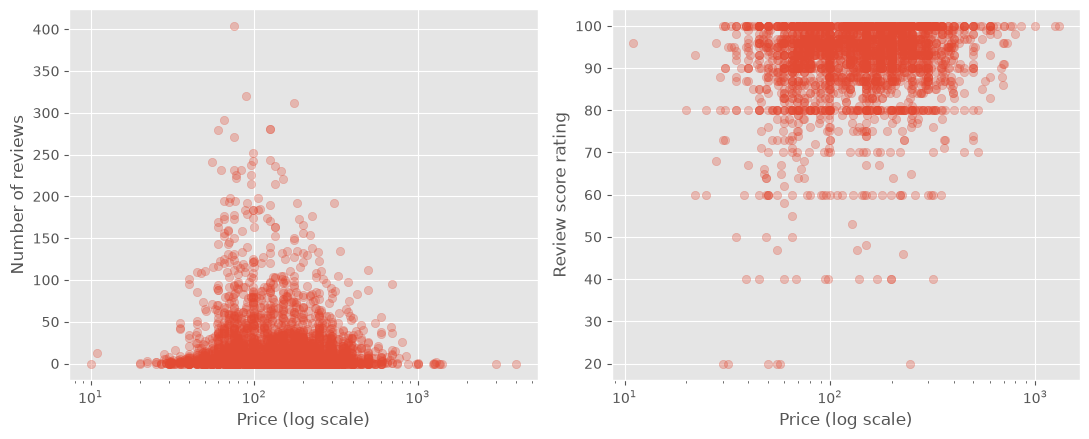

In [22]:
d_num = data[["price", "number_of_reviews"]].dropna()
d_rat = data[["price", "review_scores_rating"]].dropna()
print(len(data), len(d_num), len(d_rat))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(d_num["price"], d_num["number_of_reviews"], alpha=0.3)
axes[0].set_xscale("log")
axes[0].set_xlabel("Price (log scale)")
axes[0].set_ylabel("Number of reviews")

axes[1].scatter(d_rat["price"], d_rat["review_scores_rating"], alpha=0.3)
axes[1].set_xscale("log")
axes[1].set_xlabel("Price (log scale)")
axes[1].set_ylabel("Review score rating")
plt.tight_layout()
plt.show()

All 3,585 listings are used for the reviews question (a listing with 0 reviews is real data, not missing). Only 2,772 have a rating (the others have never been reviewed), so the ratings question uses a smaller sample.

- **Left plot:** listings with many reviews are concentrated at low to mid prices (roughly \$50 to \$250), and none above about \$700 has more than 100 reviews. But the cloud is wide: many cheap listings also have few reviews.
- **Right plot:** ratings are bunched near the top (80 to 100), so there is little room to vary, which limits how strong any correlation can be.
- I use a log axis for price so the cheap listings aren't squashed against the left edge.

The correlation coefficient summarizes the direction and strength of the association on a scale from −1 to +1. Spearman compares ranks and is robust to outliers. Pearson measures linear association and is pulled by extreme prices. If the two differ a lot, outliers are probably influencing Pearson.

In [23]:
for name, d, col in [("reviews", d_num, "number_of_reviews"),
                     ("rating", d_rat, "review_scores_rating")]:
    rp = pearsonr(d["price"], d[col])[0]
    rs = spearmanr(d["price"], d[col])[0]
    print(f"{name}: Pearson = {rp:.3f}, Spearman = {rs:.3f}")

reviews: Pearson = -0.096, Spearman = -0.077
rating: Pearson = 0.106, Spearman = 0.103


**Reviews:** Spearman ρ = −0.077, a weak negative association. More expensive listings tend to have slightly fewer reviews.
- **Ratings:** Spearman ρ = +0.103, a weak positive association (close to zero but positive). More expensive listings tend to be rated slightly higher, which goes against "no strong expectation" but is only a small effect.
- Pearson (−0.096 and 0.106) is very close to Spearman, so outliers don't seem to drive the results.
- ρ² is only about 0.6% (reviews) and 1% (ratings): price tells us almost nothing about the number of reviews or the rating of a given listing.

Permutation test
**H₀:** There is no monotonic association between price and [reviews / rating] (ρ = 0).
**H₁:** There is an association (ρ ≠ 0).
**Statistic:** Spearman correlation. **α = 0.05**, set before the test.

If H₀ is true, the pairing between a listing's price and its reviews is arbitrary. So I shuffle the review column 5,000 times, breaking any link with price, and compute the correlation each time. This shows what correlations arise by chance alone.

reviews: rho = -0.077, p = 0.0002
ratings: rho = 0.103, p = 0.0002


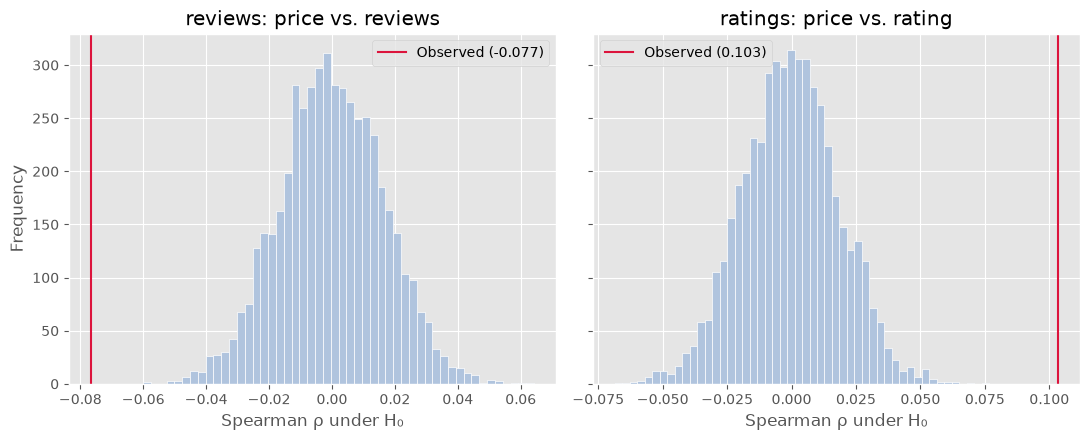

In [24]:
def perm_test_corr(x, y, n_perm=5000, seed=42):
    """Permutation test for the Spearman correlation between x and y."""
    rng = np.random.default_rng(seed)
    obs = spearmanr(x, y)[0]
    perm_rhos = np.empty(n_perm)
    for i in range(n_perm):
        perm_rhos[i] = spearmanr(y, rng.permutation(y))[0]  
    p_value = (np.sum(np.abs(perm_rhos) >= abs(obs)) + 1) / (n_perm + 1)
    return obs, perm_rhos, p_value

obs_a, perm_a, p_a = perm_test_corr(d_num["price"].values, d_num["number_of_reviews"].values)
obs_b, perm_b, p_b = perm_test_corr(d_rat["price"].values, d_rat["review_scores_rating"].values)
print(f"reviews: rho = {obs_a:.3f}, p = {p_a:.4f}")
print(f"ratings: rho = {obs_b:.3f}, p = {p_b:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, perm, obs, title in [(axes[0], perm_a, obs_a, "reviews: price vs. reviews"),
                             (axes[1], perm_b, obs_b, "ratings: price vs. rating")]:
    ax.hist(perm, bins=50, color="lightsteelblue", edgecolor="white")
    ax.axvline(obs, color="crimson", label=f"Observed ({obs:.3f})")
    ax.set_title(title)
    ax.set_xlabel("Spearman ρ under H₀")
    ax.legend()
axes[0].set_ylabel("Frequency")
plt.tight_layout()
plt.show()

he histograms show the correlations we get by chance if price and reviews/ratings are unrelated. They are centered at 0 and spread over a very small range (the standard deviation is about 1/√n ≈ 0.017 for reviews and 0.019 for ratings, so shuffled values stay roughly between −0.05 and +0.05). The observed ρ (−0.077 and +0.103) is far outside, about 4.6 and 5.4 standard deviations from 0. So I expect p to be as small as the test allows (about 0.0002 with 5,000 shuffles, i.e. report p < 0.001), and I would **reject H₀** in both cases: the associations are not due to chance.

**But** "statistically significant" does not mean "important". With n in the thousands, even a tiny correlation is detectable. Both correlations are weak (|ρ| ≈ 0.1).

Bootstrap confidence interval
To see how precisely the correlation is estimated, I resample **rows** (price and reviews together, so the pairing is preserved) with replacement 5,000 times and recompute ρ each time. The middle 95% is a confidence interval.

In [25]:
def boot_corr(x, y, n_boot=5000, seed=42):
    rng = np.random.default_rng(seed)
    n = len(x)
    out = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.integers(0, n, n)
        out[i] = spearmanr(x[idx], y[idx])[0]
    return np.percentile(out, [2.5, 97.5])

ci_a = boot_corr(d_num["price"].values, d_num["number_of_reviews"].values)
ci_b = boot_corr(d_rat["price"].values, d_rat["review_scores_rating"].values)
print(f"reviews: 95% CI {ci_a.round(3)}")
print(f"ratings: 95% CI {ci_b.round(3)}")

reviews: 95% CI [-0.109 -0.044]
ratings: 95% CI [0.065 0.141]


The 95% CI for ρ is (−0.109, −0.044) for reviews and (0.065, 0.141) for ratings. Neither interval contains 0, which agrees with the permutation test (a 95% CI that excludes 0 goes together with rejecting H₀ at α = 0.05). So the associations are very unlikely to be exactly zero.

The intervals also show how they are: even the ends of the intervals are only about ±0.14. The correlation is real but weak.

- **Correlation is not causation.** A negative price-reviews link does not mean high prices cause fewer reviews. It could come from listing age, room type or location.
- **Number of reviews depends on how long a listing has existed.** A newer listing has had less time to collect reviews. 
- **Reviews are a rough proxy for bookings.** Not every guest leaves a review.
- **Ratings are bunched near the top**, so little variation is available to correlate (a ceiling effect), and only reviewed listings have a rating, so unreviewed listings are excluded.
- **Room type and neighborhood are confounders.** Entire homes cost more and may be reviewed differently from private rooms. Repeating the analysis within one room type would help reduce this.


## **LINEAR REGRESSION**

**How much does price tend to change as the number of bedrooms increases?**

**Model:** price = β₀ + β₁ × bedrooms + error
- β₁ is the quantity of interest: dollars per additional bedroom.
- Uncertainty is measured with a bootstrap confidence interval (resampling listings) and checked against the classical formula.

I expect a clear positive slope, since larger listings should cost more.

3585 3575
bedrooms
0.0     287
1.0    2379
2.0     693
3.0     155
4.0      45
5.0      16
Name: count, dtype: int64


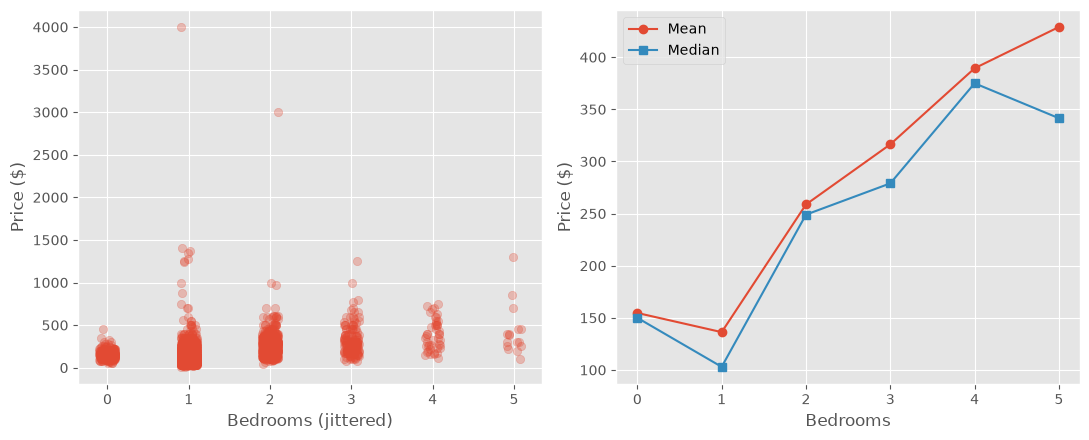

                mean  median  count
bedrooms                           
0.0       154.668990   150.0    287
1.0       136.285834   103.0   2379
2.0       258.753247   249.0    693
3.0       316.419355   279.0    155
4.0       389.400000   375.0     45
5.0       429.000000   341.5     16


In [26]:
d = data[["price", "bedrooms"]].dropna()
print(len(data), len(d))
print(d["bedrooms"].value_counts().sort_index())

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
rng = np.random.default_rng(42)
axes[0].scatter(d["bedrooms"] + rng.uniform(-0.1, 0.1, len(d)), d["price"], alpha=0.3)
axes[0].set_xlabel("Bedrooms (jittered)")
axes[0].set_ylabel("Price ($)")

g = d.groupby("bedrooms")["price"].agg(["mean", "median", "count"])
axes[1].plot(g.index, g["mean"], marker="o", label="Mean")
axes[1].plot(g.index, g["median"], marker="s", label="Median")
axes[1].set_xlabel("Bedrooms")
axes[1].set_ylabel("Price ($)")
axes[1].legend()
plt.tight_layout()
plt.show()
print(g)

Only 16 listings have 5 bedrooms and 45 have 4, so those points have little data. Also, the two extreme prices (\$4,000 and \$3,000) visible in the left plot can pull the slope. We could consider restricting to 0 to 4 bedrooms or checking the fit without those two points.

In [27]:
X = sm.add_constant(d["bedrooms"])
model = sm.OLS(d["price"], X).fit()
print(model.summary().tables[1])
print(f"R² = {model.rsquared:.3f}")

b0, b1 = model.params

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         78.3747      4.458     17.580      0.000      69.634      87.116
bedrooms      75.9849      3.045     24.958      0.000      70.016      81.954
R² = 0.148


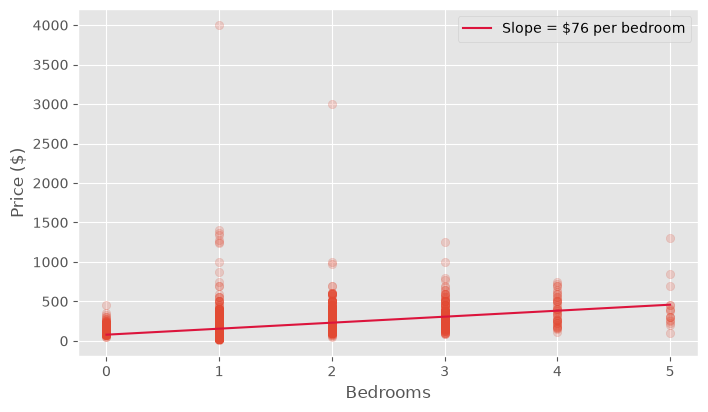

In [28]:
fig, ax = plt.subplots()
ax.scatter(d["bedrooms"], d["price"], alpha=0.2)
xs = np.linspace(d["bedrooms"].min(), d["bedrooms"].max(), 50)
ax.plot(xs, b0 + b1 * xs, color="crimson", label=f"Slope = ${b1:.0f} per bedroom")
ax.set_xlabel("Bedrooms")
ax.set_ylabel("Price ($)")
ax.legend()
plt.show()

- **Slope:** on average, each additional bedroom is associated with about **\$76 more** per night (β₁ = 75.98, std. error 3.05, t ≈ 25, p < 0.001, so the slope is clearly not 0). Say "associated with", not "causes": a bedroom is also linked to size, room type and location.
- **Intercept:** β₀ = \$78 is the fitted price for 0 bedrooms (a studio). But the actual average price of studios is about \$155, so the line is far from the data there. When the line doesn't fit well at an end, the intercept is just where the line crosses the axis, not a real estimate of studio prices.
- **R² = 0.148:** bedrooms alone explain about 14.8% of the variation in price. The rest comes from location, quality, room type and so on.

The slope comes from one dataset, so a different sample would give a slightly different line. I resample the listings (price and bedrooms together) with replacement 5,000 times, refit the line each time, and record the slope. The middle 95% is a confidence interval.

Bootstrap 95% CI for slope: (68.9, 83.5)
Classical 95% CI: [70. 82.]


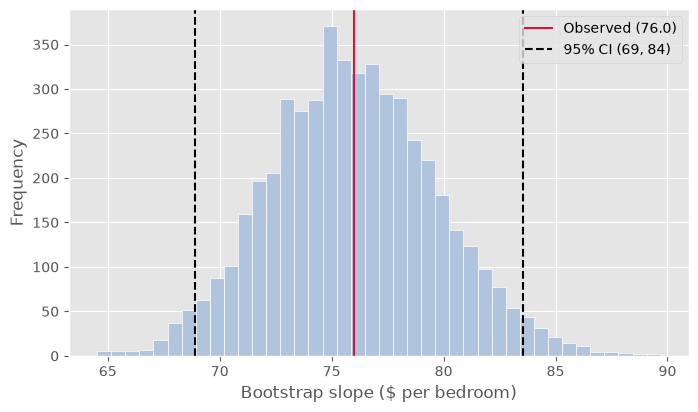

In [29]:

rng = np.random.default_rng(42)
x, y = d["bedrooms"].values, d["price"].values
n = len(d)

boot_slopes = np.empty(5000)
for i in range(5000):
    idx = rng.integers(0, n, n)
    boot_slopes[i] = np.polyfit(x[idx], y[idx], 1)[0]

ci = np.percentile(boot_slopes, [2.5, 97.5])
print(f"Bootstrap 95% CI for slope: ({ci[0]:.1f}, {ci[1]:.1f})")
print("Classical 95% CI:", model.conf_int().loc["bedrooms"].round(1).values)

fig, ax = plt.subplots()
ax.hist(boot_slopes, bins=40, color="lightsteelblue", edgecolor="white")
ax.axvline(b1, color="crimson", label=f"Observed ({b1:.1f})")
ax.axvline(ci[0], color="black", linestyle="--", label=f"95% CI ({ci[0]:.0f}, {ci[1]:.0f})")
ax.axvline(ci[1], color="black", linestyle="--")
ax.set_xlabel("Bootstrap slope ($ per bedroom)")
ax.set_ylabel("Frequency")
ax.legend()
plt.show()

The 95% bootstrap CI for the slope is (68.9, 83.5) dollars per bedroom, so the true average difference per extra bedroom is plausibly in that range. The classical interval (70.0, 82.0) is close, which gives extra confidence in the result.

The bootstrap interval is a bit wider. A likely reason: the classical formula assumes prices vary equally at every number of bedrooms, but they vary more for larger listings and there are extreme prices. The bootstrap doesn't make that assumption, so here it is the more trustworthy of the two.

The CI describes uncertainty in the average change. An individual listing can sit far above or below the line.

**Robustness check with log price.**
Prices are right-skewed, so I also fit log(price) on bedrooms. A slope b in a log model means "price is multiplied by e^b per extra bedroom", i.e. a **percentage** change.

In [30]:
m_log = sm.OLS(np.log(d["price"]), X).fit()
pct = (np.exp(m_log.params["bedrooms"]) - 1) * 100
print(f"Each extra bedroom ≈ {pct:.0f}% higher price, R² = {m_log.rsquared:.3f}")

Each extra bedroom ≈ 44% higher price, R² = 0.179


In the log model, each extra bedroom is associated with about 44% higher price. This agrees with the linear model in direction (more bedrooms, higher price) but describes a multiplicative effect rather than a constant \$76 step. A percentage fits the data better: \$76 more is a big jump for a \$100 listing, but a smaller one for a \$400 listing, and expensive listings vary more.